In [1]:
import sys

print("Python version:", sys.version)
print("Environment ready!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Environment ready!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Libraries imported successfully!


In [3]:
# Load the STAR raw count matrix
counts = pd.read_csv(
    "/content/GLDS-104_rna_seq_STAR_Unnormalized_Counts_GLbulkRNAseq.csv"
)

# Load the sample metadata
metadata = pd.read_csv(
    "/content/GLDS-104_rna_seq_SampleTable_GLbulkRNAseq.csv"
)

print("Count matrix shape:", counts.shape)
print("Metadata shape:", metadata.shape)

print("\nCount matrix preview:")
display(counts.head())

print("\nMetadata preview:")
display(metadata.head())

Count matrix shape: (57186, 13)
Metadata shape: (12, 2)

Count matrix preview:


,Unnamed: 0,Mmus_C57-6J_SLS_FLT_Rep1_M23,Mmus_C57-6J_SLS_FLT_Rep2_M24,Mmus_C57-6J_SLS_FLT_Rep3_M25,Mmus_C57-6J_SLS_FLT_Rep4_M26,Mmus_C57-6J_SLS_FLT_Rep5_M27,Mmus_C57-6J_SLS_FLT_Rep6_M28,Mmus_C57-6J_SLS_GC_Rep1_M33,Mmus_C57-6J_SLS_GC_Rep2_M34,Mmus_C57-6J_SLS_GC_Rep3_M35,Mmus_C57-6J_SLS_GC_Rep4_M36,Mmus_C57-6J_SLS_GC_Rep5_M37,Mmus_C57-6J_SLS_GC_Rep6_M38
0,ENSMUSG00000000001,895,739,862,907,1116,721,1254,929,1104,910,916,931
1,ENSMUSG00000000003,0,0,0,0,0,0,0,0,0,0,0,0
2,ENSMUSG00000000028,90,124,88,135,194,107,151,119,130,111,118,138
3,ENSMUSG00000000031,58637,55339,72974,77204,60217,47676,122000,89223,108426,97519,92017,101387
4,ENSMUSG00000000037,8,5,6,10,13,3,23,8,8,4,3,13



Metadata preview:


,Unnamed: 0,condition
0,Mmus_C57-6J_SLS_GC_Rep1_M33,Ground.Control
1,Mmus_C57-6J_SLS_GC_Rep2_M34,Ground.Control
2,Mmus_C57-6J_SLS_GC_Rep3_M35,Ground.Control
3,Mmus_C57-6J_SLS_GC_Rep4_M36,Ground.Control
4,Mmus_C57-6J_SLS_GC_Rep5_M37,Ground.Control


In [4]:
# Inspect the column names
print("Count matrix sample columns:")
print(counts.columns.tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nAll metadata samples and conditions:")
display(metadata)

print("\nSamples per condition:")
print(metadata["condition"].value_counts())

Count matrix sample columns:
['Unnamed: 0', 'Mmus_C57-6J_SLS_FLT_Rep1_M23', 'Mmus_C57-6J_SLS_FLT_Rep2_M24', 'Mmus_C57-6J_SLS_FLT_Rep3_M25', 'Mmus_C57-6J_SLS_FLT_Rep4_M26', 'Mmus_C57-6J_SLS_FLT_Rep5_M27', 'Mmus_C57-6J_SLS_FLT_Rep6_M28', 'Mmus_C57-6J_SLS_GC_Rep1_M33', 'Mmus_C57-6J_SLS_GC_Rep2_M34', 'Mmus_C57-6J_SLS_GC_Rep3_M35', 'Mmus_C57-6J_SLS_GC_Rep4_M36', 'Mmus_C57-6J_SLS_GC_Rep5_M37', 'Mmus_C57-6J_SLS_GC_Rep6_M38']

Metadata columns:
['Unnamed: 0', 'condition']

All metadata samples and conditions:


,Unnamed: 0,condition
0,Mmus_C57-6J_SLS_GC_Rep1_M33,Ground.Control
1,Mmus_C57-6J_SLS_GC_Rep2_M34,Ground.Control
2,Mmus_C57-6J_SLS_GC_Rep3_M35,Ground.Control
3,Mmus_C57-6J_SLS_GC_Rep4_M36,Ground.Control
4,Mmus_C57-6J_SLS_GC_Rep5_M37,Ground.Control
5,Mmus_C57-6J_SLS_GC_Rep6_M38,Ground.Control
6,Mmus_C57-6J_SLS_FLT_Rep1_M23,Space.Flight
7,Mmus_C57-6J_SLS_FLT_Rep2_M24,Space.Flight
8,Mmus_C57-6J_SLS_FLT_Rep3_M25,Space.Flight
9,Mmus_C57-6J_SLS_FLT_Rep4_M26,Space.Flight



Samples per condition:
condition
Ground.Control    6
Space.Flight      6
Name: count, dtype: int64


In [5]:
# Extract gene IDs from the first column
counts = counts.rename(columns={"Unnamed: 0": "gene_id"})
counts = counts.set_index("gene_id")

# Extract sample IDs from the metadata
metadata = metadata.rename(columns={"Unnamed: 0": "sample_id"})
metadata = metadata.set_index("sample_id")

# Check that both files contain exactly the same samples
count_samples = set(counts.columns)
metadata_samples = set(metadata.index)

assert count_samples == metadata_samples, "Sample names do not match!"

# Reorder count matrix to match metadata order
counts = counts.loc[:, metadata.index]

# Verify the alignment
assert list(counts.columns) == list(metadata.index), "Sample order mismatch!"

print("Sample alignment successful!")
print("Count matrix shape:", counts.shape)
print("Metadata shape:", metadata.shape)

print("\nAligned sample order:")
print(counts.columns.tolist())

Sample alignment successful!
Count matrix shape: (57186, 12)
Metadata shape: (12, 1)

Aligned sample order:
['Mmus_C57-6J_SLS_GC_Rep1_M33', 'Mmus_C57-6J_SLS_GC_Rep2_M34', 'Mmus_C57-6J_SLS_GC_Rep3_M35', 'Mmus_C57-6J_SLS_GC_Rep4_M36', 'Mmus_C57-6J_SLS_GC_Rep5_M37', 'Mmus_C57-6J_SLS_GC_Rep6_M38', 'Mmus_C57-6J_SLS_FLT_Rep1_M23', 'Mmus_C57-6J_SLS_FLT_Rep2_M24', 'Mmus_C57-6J_SLS_FLT_Rep3_M25', 'Mmus_C57-6J_SLS_FLT_Rep4_M26', 'Mmus_C57-6J_SLS_FLT_Rep5_M27', 'Mmus_C57-6J_SLS_FLT_Rep6_M28']


In [6]:
# Check data types
print("Data types:")
print(counts.dtypes.value_counts())

# Check for missing values
print("\nMissing values:", counts.isna().sum().sum())

# Check for negative values
print("Negative values:", (counts < 0).sum().sum())

# Check for fractional counts
print("Fractional values:", (counts % 1 != 0).sum().sum())

# Check duplicate gene IDs
print("Duplicate gene IDs:", counts.index.duplicated().sum())

# Check for genes with all-zero counts
print("All-zero genes:", (counts.sum(axis=1) == 0).sum())

# Summary
print("\nValidation complete!")

Data types:
int64    12
Name: count, dtype: int64

Missing values: 0
Negative values: 0
Fractional values: 0
Duplicate gene IDs: 0
All-zero genes: 24649

Validation complete!


In [7]:
# Total counts per sample
total_counts = counts.sum(axis=0)

# Number of genes with at least one count per sample
detected_genes = (counts > 0).sum(axis=0)

# Combine QC metrics into a table
qc_summary = pd.DataFrame({
    "Condition": metadata["condition"],
    "Total_Counts": total_counts,
    "Detected_Genes": detected_genes
})

display(qc_summary)

,Condition,Total_Counts,Detected_Genes
Mmus_C57-6J_SLS_GC_Rep1_M33,Ground.Control,61928808,24445
Mmus_C57-6J_SLS_GC_Rep2_M34,Ground.Control,53149828,23190
Mmus_C57-6J_SLS_GC_Rep3_M35,Ground.Control,61161507,23792
Mmus_C57-6J_SLS_GC_Rep4_M36,Ground.Control,53846661,24296
Mmus_C57-6J_SLS_GC_Rep5_M37,Ground.Control,54078041,23987
Mmus_C57-6J_SLS_GC_Rep6_M38,Ground.Control,51850507,23659
Mmus_C57-6J_SLS_FLT_Rep1_M23,Space.Flight,48047703,23803
Mmus_C57-6J_SLS_FLT_Rep2_M24,Space.Flight,46674612,23929
Mmus_C57-6J_SLS_FLT_Rep3_M25,Space.Flight,55547094,24415
Mmus_C57-6J_SLS_FLT_Rep4_M26,Space.Flight,55715992,24312


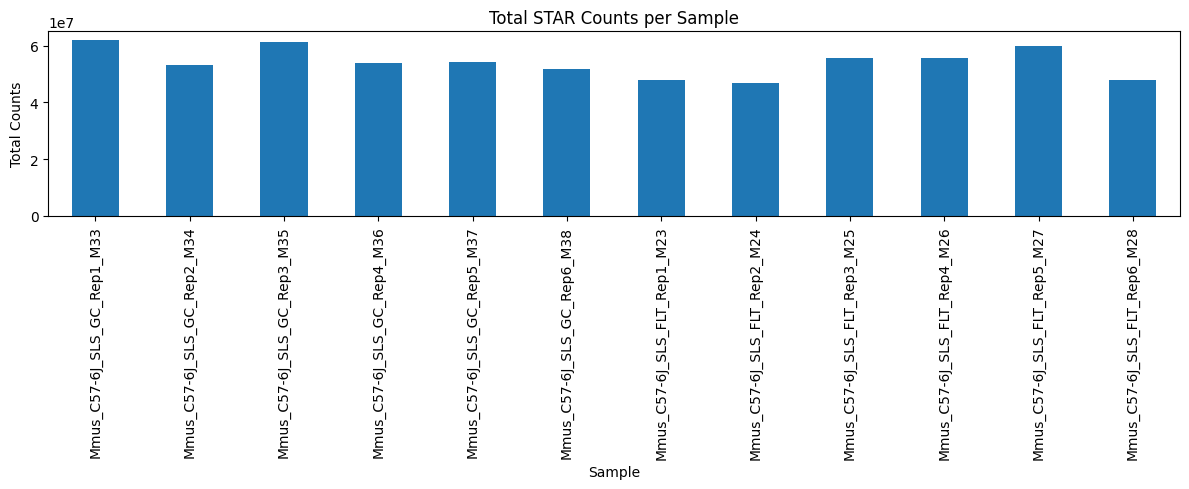

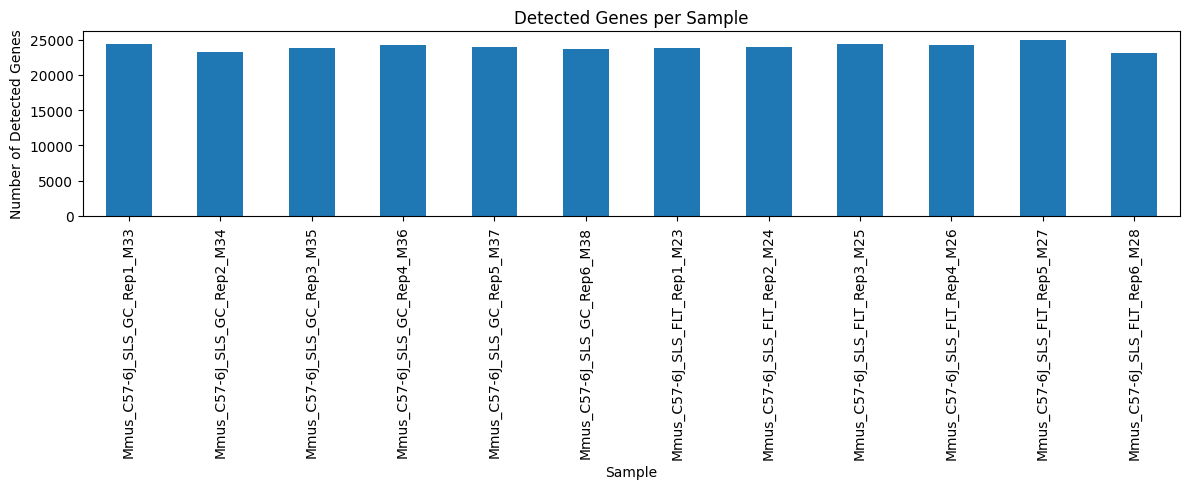

In [8]:
# Plot total counts per sample
plt.figure(figsize=(12, 5))
total_counts.plot(kind="bar")

plt.title("Total STAR Counts per Sample")
plt.xlabel("Sample")
plt.ylabel("Total Counts")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# Plot detected genes per sample
plt.figure(figsize=(12, 5))
detected_genes.plot(kind="bar")

plt.title("Detected Genes per Sample")
plt.xlabel("Sample")
plt.ylabel("Number of Detected Genes")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
# Calculate library size (total counts) for each sample
library_sizes = counts.sum(axis=0)

# Convert raw counts to counts per million (CPM)
cpm = counts.div(library_sizes, axis=1) * 1_000_000

# Log2-transform CPM values
log_cpm = np.log2(cpm + 1)

print("Log-CPM matrix shape:", log_cpm.shape)
print("\nPreview:")
display(log_cpm.iloc[:5, :5])

Log-CPM matrix shape: (57186, 12)

Preview:


,Mmus_C57-6J_SLS_GC_Rep1_M33,Mmus_C57-6J_SLS_GC_Rep2_M34,Mmus_C57-6J_SLS_GC_Rep3_M35,Mmus_C57-6J_SLS_GC_Rep4_M36,Mmus_C57-6J_SLS_GC_Rep5_M37
gene_id,,,,,
ENSMUSG00000000001,4.409327,4.207806,4.251762,4.161875,4.164986
ENSMUSG00000000003,0.000000,0.000000,0.000000,0.000000,0.000000
ENSMUSG00000000028,1.781689,1.695528,1.644096,1.614196,1.669948
ENSMUSG00000000031,10.944715,10.713994,10.792613,10.823407,10.733489
ENSMUSG00000000037,0.455643,0.202283,0.177345,0.103377,0.077893


In [10]:
# Calculate variance across the 12 samples for each gene
gene_variance = log_cpm.var(axis=1)

# Select the 500 genes with the highest variance
top_variable_genes = gene_variance.nlargest(500).index

# Create a PCA input matrix containing only these genes
pca_input = log_cpm.loc[top_variable_genes]

print("PCA input shape:", pca_input.shape)
print("Number of selected genes:", len(top_variable_genes))

print("\nTop 10 most variable genes:")
display(gene_variance.nlargest(10))

PCA input shape: (500, 12)
Number of selected genes: 500

Top 10 most variable genes:


gene_id
ENSMUSG00000083365    6.502023
ENSMUSG00000046828    2.888048
ENSMUSG00000029368    2.341956
ENSMUSG00000057003    2.181649
ENSMUSG00000024803    2.160194
ENSMUSG00000053025    2.048715
ENSMUSG00000075053    1.852961
ENSMUSG00000048852    1.780042
ENSMUSG00000054889    1.668956
ENSMUSG00000040485    1.662604
dtype: float64

In [11]:
from sklearn.decomposition import PCA

# Transpose so rows = samples and columns = genes
pca_data = pca_input.T

# Perform PCA
pca = PCA(n_components=2)
pca_results = pca.fit_transform(pca_data)

# Create a PCA results table
pca_df = pd.DataFrame(
    pca_results,
    columns=["PC1", "PC2"],
    index=pca_data.index
)

# Add experimental condition
pca_df["Condition"] = metadata["condition"].values

# Calculate percentage of variance explained
explained_variance = pca.explained_variance_ratio_ * 100

print("PCA completed!")
print("\nVariance explained:")
print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")

print("\nPCA results:")
display(pca_df)

PCA completed!

Variance explained:
PC1: 59.93%
PC2: 8.13%

PCA results:


,PC1,PC2,Condition
Mmus_C57-6J_SLS_GC_Rep1_M33,-11.481699,-0.839300,Ground.Control
Mmus_C57-6J_SLS_GC_Rep2_M34,-14.018768,-1.081059,Ground.Control
Mmus_C57-6J_SLS_GC_Rep3_M35,-11.042099,-1.565845,Ground.Control
Mmus_C57-6J_SLS_GC_Rep4_M36,-9.078677,1.183341,Ground.Control
Mmus_C57-6J_SLS_GC_Rep5_M37,-11.123937,0.451167,Ground.Control
Mmus_C57-6J_SLS_GC_Rep6_M38,-11.729036,0.700141,Ground.Control
Mmus_C57-6J_SLS_FLT_Rep1_M23,11.729760,-6.934221,Space.Flight
Mmus_C57-6J_SLS_FLT_Rep2_M24,12.913801,-7.920045,Space.Flight
Mmus_C57-6J_SLS_FLT_Rep3_M25,7.906130,2.711516,Space.Flight
Mmus_C57-6J_SLS_FLT_Rep4_M26,14.374047,0.256220,Space.Flight


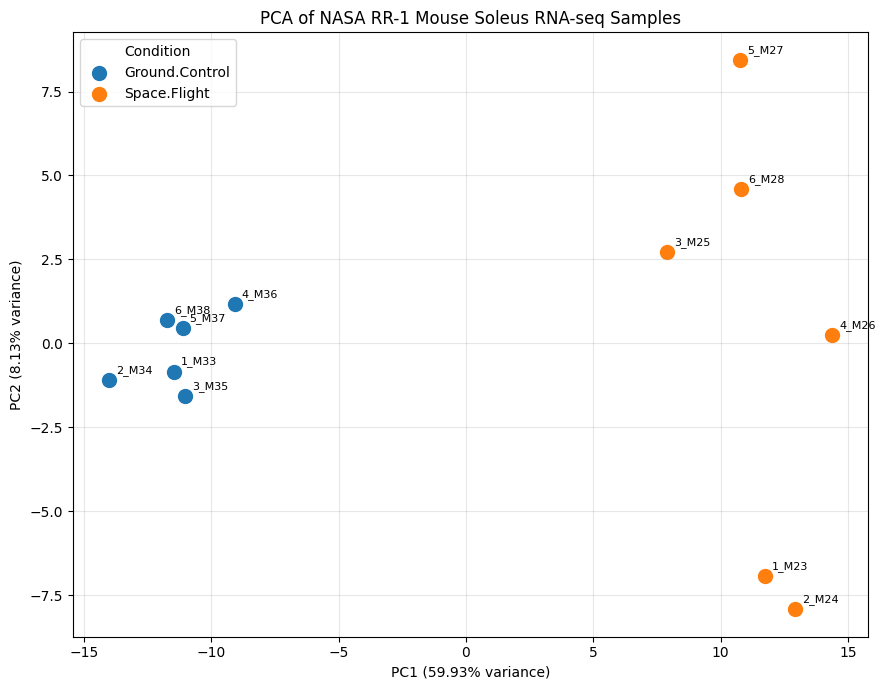

In [12]:
# Create PCA scatter plot
plt.figure(figsize=(9, 7))

for condition in pca_df["Condition"].unique():
    subset = pca_df[pca_df["Condition"] == condition]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=condition,
        s=100
    )

# Add sample labels
for sample in pca_df.index:
    plt.annotate(
        sample.split("_Rep")[1],
        (pca_df.loc[sample, "PC1"], pca_df.loc[sample, "PC2"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(f"PC1 ({explained_variance[0]:.2f}% variance)")
plt.ylabel(f"PC2 ({explained_variance[1]:.2f}% variance)")
plt.title("PCA of NASA RR-1 Mouse Soleus RNA-seq Samples")
plt.legend(title="Condition")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
!pip install pydeseq2

In [14]:
# Prepare metadata for differential expression analysis

# Set Ground Control as the reference group
metadata["condition"] = pd.Categorical(
    metadata["condition"],
    categories=["Ground.Control", "Space.Flight"]
)

# PyDESeq2 expects samples as rows and genes as columns
counts_pydeseq = counts.T

# Verify that sample order matches between counts and metadata
assert list(counts_pydeseq.index) == list(metadata.index)

# Verify counts are integers
assert np.issubdtype(counts_pydeseq.values.dtype, np.integer)

print("PyDESeq2 data preparation successful!")
print("Counts shape (samples × genes):", counts_pydeseq.shape)
print("Metadata shape:", metadata.shape)

print("\nCondition order:")
print(metadata["condition"].cat.categories.tolist())

print("\nSamples per condition:")
print(metadata["condition"].value_counts())

print("\nCounts preview:")
display(counts_pydeseq.iloc[:5, :5])

PyDESeq2 data preparation successful!
Counts shape (samples × genes): (12, 57186)
Metadata shape: (12, 1)

Condition order:
['Ground.Control', 'Space.Flight']

Samples per condition:
condition
Ground.Control    6
Space.Flight      6
Name: count, dtype: int64

Counts preview:


gene_id,ENSMUSG00000000001,ENSMUSG00000000003,ENSMUSG00000000028,ENSMUSG00000000031,ENSMUSG00000000037
Mmus_C57-6J_SLS_GC_Rep1_M33,1254,0,151,122000,23
Mmus_C57-6J_SLS_GC_Rep2_M34,929,0,119,89223,8
Mmus_C57-6J_SLS_GC_Rep3_M35,1104,0,130,108426,8
Mmus_C57-6J_SLS_GC_Rep4_M36,910,0,111,97519,4
Mmus_C57-6J_SLS_GC_Rep5_M37,916,0,118,92017,3


In [15]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# Create the PyDESeq2 dataset object
dds = DeseqDataSet(
    counts=counts_pydeseq,
    metadata=metadata,
    design="~condition",
    refit_cooks=True,
    n_cpus=4
)

print("PyDESeq2 dataset object created successfully!")
print("Number of samples:", dds.n_obs)
print("Number of genes:", dds.n_vars)

PyDESeq2 dataset object created successfully!
Number of samples: 12
Number of genes: 57186


In [16]:
# Fit the DESeq2 model
dds.deseq2()

print("PyDESeq2 model fitting completed!")

PyDESeq2 model fitting completed!


In [17]:
# Calculate differential-expression statistics
stat_res = DeseqStats(
    dds,
    contrast=["condition", "Space.Flight", "Ground.Control"],
    n_cpus=4
)

stat_res.summary()

# Extract results into a DataFrame
results_pydeseq = stat_res.results_df

print("\nDifferential-expression results:")
print("Results shape:", results_pydeseq.shape)

display(results_pydeseq.head())

Log2 fold change & Wald test p-value: condition Space.Flight vs Ground.Control
                        baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                                
ENSMUSG00000000001    926.488974       -0.054164  0.064308 -0.842256   
ENSMUSG00000000003      0.000000             NaN       NaN       NaN   
ENSMUSG00000000028    123.606904        0.082775  0.144909  0.571219   
ENSMUSG00000000031  80133.879533       -0.558862  0.083827 -6.666826   
ENSMUSG00000000037      8.284576       -0.246091  0.486179 -0.506174   
...                          ...             ...       ...       ...   
ENSMUSG00002076988      0.000000             NaN       NaN       NaN   
ENSMUSG00002076989      0.413494        0.607493  2.043200  0.297324   
ENSMUSG00002076990      0.000000             NaN       NaN       NaN   
ENSMUSG00002076991      0.000000             NaN       NaN       NaN   
ENSMUSG00002076992      0.000000             NaN       Na

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_id,,,,,,
ENSMUSG00000000001,926.488974,-0.054164,0.064308,-0.842256,3.996448e-01,5.904246e-01
ENSMUSG00000000003,0.000000,NaN,NaN,NaN,NaN,NaN
ENSMUSG00000000028,123.606904,0.082775,0.144909,0.571219,5.678510e-01,7.344688e-01
ENSMUSG00000000031,80133.879533,-0.558862,0.083827,-6.666826,2.613949e-11,7.243204e-10
ENSMUSG00000000037,8.284576,-0.246091,0.486179,-0.506174,6.127348e-01,7.667762e-01


In [18]:
# Count genes with valid adjusted p-values
valid_results = results_pydeseq.dropna(subset=["padj"])

# Identify statistically significant genes
significant_genes = valid_results[valid_results["padj"] < 0.05]

# Separate genes by direction of expression change
upregulated_flight = significant_genes[
    significant_genes["log2FoldChange"] > 0
]

downregulated_flight = significant_genes[
    significant_genes["log2FoldChange"] < 0
]

# Summarize results
print("PyDESeq2 Full-Data Results")
print("-------------------------")
print("Total genes analyzed:", len(results_pydeseq))
print("Genes with valid adjusted p-values:", len(valid_results))
print("Significant genes (padj < 0.05):", len(significant_genes))
print("Higher expression in Flight:", len(upregulated_flight))
print("Higher expression in Ground Control:", len(downregulated_flight))

print("\nTop 10 significant genes:")
display(
    significant_genes
    .sort_values("padj")
    .head(10)
)

PyDESeq2 Full-Data Results
-------------------------
Total genes analyzed: 57186
Genes with valid adjusted p-values: 20339
Significant genes (padj < 0.05): 5654
Higher expression in Flight: 2733
Higher expression in Ground Control: 2921

Top 10 significant genes:


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_id,,,,,,
ENSMUSG00000073535,569.942007,-2.091803,0.093479,-22.377264,6.554467e-111,1.333113e-106
ENSMUSG00000024063,1732.367731,-1.429029,0.070179,-20.362655,3.586146e-92,3.646931e-88
ENSMUSG00000006576,804.932240,-1.816292,0.089586,-20.274193,2.173251e-91,1.473392e-87
ENSMUSG00000028444,645.342162,2.479796,0.134050,18.498984,2.104044e-76,1.069854e-72
ENSMUSG00000057948,148.381614,-3.786548,0.209913,-18.038648,9.688609e-73,3.941132e-69
ENSMUSG00000025085,27538.068092,-1.773282,0.100283,-17.682828,5.687030e-70,1.927809e-66
ENSMUSG00000068697,20346.346054,1.029622,0.059339,17.351539,1.920290e-67,5.579540e-64
ENSMUSG00000033576,4401.613051,-1.085025,0.063961,-16.963937,1.518234e-64,3.859920e-61
ENSMUSG00000023828,207.874862,2.139968,0.127337,16.805594,2.220775e-63,5.018706e-60


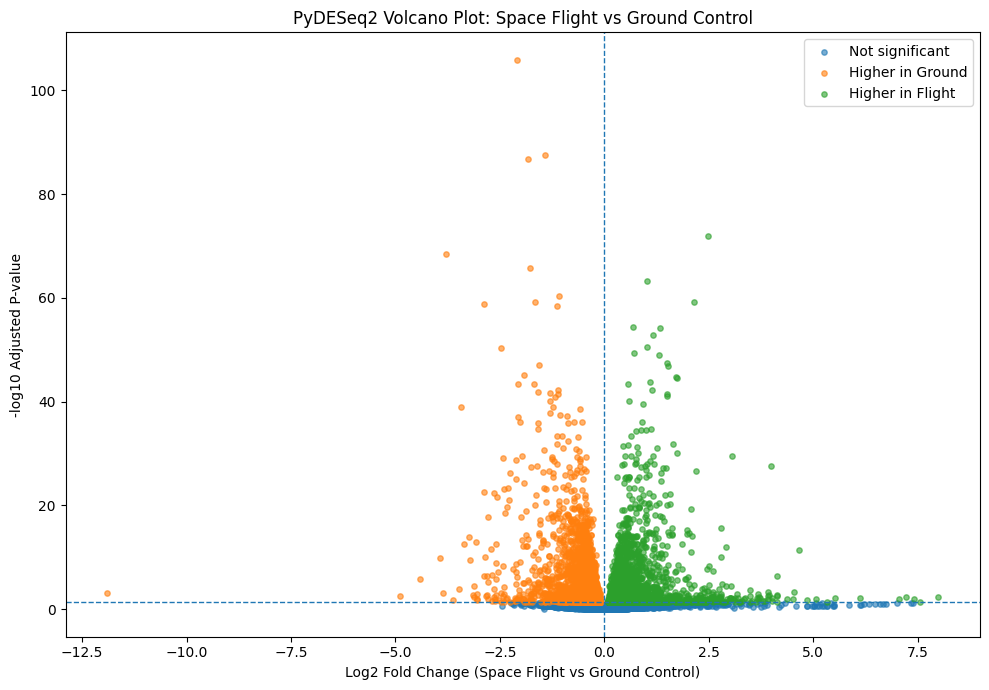

In [19]:
# Prepare volcano plot data
volcano_data = results_pydeseq.dropna(subset=["padj", "log2FoldChange"]).copy()

# Calculate -log10 adjusted p-value
volcano_data["-log10_padj"] = -np.log10(
    volcano_data["padj"].clip(lower=1e-300)
)

# Define significance categories
volcano_data["Significance"] = "Not significant"

volcano_data.loc[
    (volcano_data["padj"] < 0.05) &
    (volcano_data["log2FoldChange"] > 0),
    "Significance"
] = "Higher in Flight"

volcano_data.loc[
    (volcano_data["padj"] < 0.05) &
    (volcano_data["log2FoldChange"] < 0),
    "Significance"
] = "Higher in Ground"

# Plot
plt.figure(figsize=(10, 7))

for category in volcano_data["Significance"].unique():
    subset = volcano_data[volcano_data["Significance"] == category]

    plt.scatter(
        subset["log2FoldChange"],
        subset["-log10_padj"],
        label=category,
        alpha=0.6,
        s=15
    )

# Significance threshold
plt.axhline(
    -np.log10(0.05),
    linestyle="--",
    linewidth=1
)

# No-change reference
plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Log2 Fold Change (Space Flight vs Ground Control)")
plt.ylabel("-log10 Adjusted P-value")
plt.title("PyDESeq2 Volcano Plot: Space Flight vs Ground Control")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Save the complete PyDESeq2 differential-expression results
results_pydeseq.to_csv(
    "PyDESeq2_FullData_Results.csv"
)

print("PyDESeq2 reference results saved!")

PyDESeq2 reference results saved!


In [21]:
!pip install inmoose

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 4.9 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for inmoose: filename=inmoose-0.9.1-cp313-cp313-linux_x86_64.whl size=5046461 sha256=201646ee8bac976a46ddabb63d1fbd3e294a35d05f106feef88442cd00e2e1e0
  Stored in directory: /root/.cache/pip/wheels/e0/d1/ec/1298d85610ca694cf48d2804a23ed0eda061880d9e75f0b9b8
Successfully built inmoose
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [inmoose]


In [22]:
# Import edgeR-compatible functions from InMoose
from inmoose.edgepy import DGEList, glmLRT, topTags
from patsy import dmatrix

print("InMoose edgepy imports successful!")

InMoose edgepy imports successful!


In [23]:
# Create the experimental design matrix
design = dmatrix(
    "~ condition",
    metadata,
    return_type="dataframe"
)

print("Design matrix:")
display(design)

Design matrix:


,Intercept,condition[T.Space.Flight]
sample_id,,
Mmus_C57-6J_SLS_GC_Rep1_M33,1.0,0.0
Mmus_C57-6J_SLS_GC_Rep2_M34,1.0,0.0
Mmus_C57-6J_SLS_GC_Rep3_M35,1.0,0.0
Mmus_C57-6J_SLS_GC_Rep4_M36,1.0,0.0
Mmus_C57-6J_SLS_GC_Rep5_M37,1.0,0.0
Mmus_C57-6J_SLS_GC_Rep6_M38,1.0,0.0
Mmus_C57-6J_SLS_FLT_Rep1_M23,1.0,1.0
Mmus_C57-6J_SLS_FLT_Rep2_M24,1.0,1.0
Mmus_C57-6J_SLS_FLT_Rep3_M25,1.0,1.0


In [25]:
# Create the edgeR DGEList object
dge_list = DGEList(
    counts=counts,
    samples=metadata,
    group_col="condition"
)

print("DGEList object created successfully!")
print("Genes:", dge_list.counts.shape[0])
print("Samples:", dge_list.counts.shape[1])

DGEList object created successfully!
Genes: 57186
Samples: 12


In [28]:
# Estimate common dispersion using the experimental design
dge_list.estimateGLMCommonDisp(
    design=design
)

print("Common dispersion estimation completed!")

# Display estimated dispersion
print("Common dispersion:", dge_list.common_dispersion)

Common dispersion estimation completed!
Common dispersion: 0.018591924643306425


In [27]:
# # Inspect available methods in our DGEList object
# print("Available DGEList methods:")
# print([method for method in dir(dge_list) if not method.startswith("_")])

Available DGEList methods:
['AveLogCPM', 'aveLogCPM', 'common_dispersion', 'counts', 'design', 'estimateGLMCommonDisp', 'estimateGLMTagwiseDisp', 'genes', 'getDispersion', 'getOffset', 'glmFit', 'glmQLFit', 'offset', 'predFC', 'prior_df', 'samples', 'splitIntoGroups', 'tagwise_dispersion', 'trended_dispersion', 'weights']


In [29]:
import inspect

print("glmFit signature:")
print(inspect.signature(dge_list.glmFit))

glmFit signature:
(design=None, dispersion=None, prior_count=0.125, start=None)


In [30]:
# Fit the generalized linear model
glm_fit = dge_list.glmFit(
    design=design,
    dispersion=dge_list.common_dispersion
)

print("GLM fitting completed successfully!")

GLM fitting completed successfully!


In [31]:
import inspect

print("glmLRT signature:")
print(inspect.signature(glmLRT))

glmLRT signature:
(glmfit, coef=None, contrast=None)


In [32]:
# Perform the likelihood-ratio test
lrt_results = glmLRT(glm_fit)

print("edgeR-style likelihood-ratio test completed!")

edgeR-style likelihood-ratio test completed!


In [33]:
# Inspect the likelihood-ratio test results
print("Result type:", type(lrt_results))
print("\nAvailable attributes:")
print([attribute for attribute in dir(lrt_results) if not attribute.startswith("_")])

Result type: <class 'inmoose.edgepy.DGELRT.DGELRT'>

Available attributes:
['T', 'abs', 'add', 'add_prefix', 'add_suffix', 'agg', 'aggregate', 'align', 'all', 'any', 'apply', 'asfreq', 'asof', 'assign', 'astype', 'at', 'at_time', 'attrs', 'axes', 'between_time', 'bfill', 'boxplot', 'clip', 'columns', 'combine', 'combine_first', 'compare', 'comparison', 'convert_dtypes', 'copy', 'corr', 'corrwith', 'count', 'cov', 'cummax', 'cummin', 'cumprod', 'cumsum', 'describe', 'description', 'df_test', 'diff', 'div', 'divide', 'dot', 'drop', 'drop_duplicates', 'droplevel', 'dropna', 'dtypes', 'duplicated', 'empty', 'eq', 'equals', 'eval', 'ewm', 'expanding', 'explode', 'ffill', 'fillna', 'filter', 'first_valid_index', 'fit', 'flags', 'floordiv', 'from_arrow', 'from_dict', 'from_records', 'ge', 'genes', 'get', 'groupby', 'gt', 'head', 'hist', 'iat', 'idxmax', 'idxmin', 'iloc', 'index', 'infer_objects', 'info', 'insert', 'interpolate', 'isetitem', 'isin', 'isna', 'isnull', 'items', 'iterrows', 'iter

In [34]:
print("Results shape:", lrt_results.shape)
print("\nColumns:")
print(lrt_results.columns.tolist())

print("\nFirst 5 results:")
display(lrt_results.head())

Results shape: (57186, 5)

Columns:
['log2FoldChange', 'lfcSE', 'logCPM', 'stat', 'pvalue']

First 5 results:


,log2FoldChange,lfcSE,logCPM,stat,pvalue
gene_id,,,,,
ENSMUSG00000000001,-0.106471,0.009460,4.115349,0.830814,3.620371e-01
ENSMUSG00000000003,0.000000,0.000000,-4.759035,0.000000,1.000000e+00
ENSMUSG00000000028,0.034433,0.012804,1.231563,0.064358,7.997354e-01
ENSMUSG00000000031,-0.616151,0.008947,10.550298,29.191141,6.557835e-08
ENSMUSG00000000037,-0.287619,0.065677,-2.348872,0.906166,3.411337e-01


In [35]:
from statsmodels.stats.multitest import multipletests

# Copy edgeR results
results_edger = lrt_results.copy()

# Calculate Benjamini-Hochberg adjusted p-values
results_edger["padj"] = multipletests(
    results_edger["pvalue"],
    method="fdr_bh"
)[1]

print("BH adjustment completed!")
print("Results shape:", results_edger.shape)
print("\nFirst 5 rows:")
display(results_edger.head())

BH adjustment completed!
Results shape: (57186, 6)

First 5 rows:


,log2FoldChange,lfcSE,logCPM,stat,pvalue,padj
gene_id,,,,,,
ENSMUSG00000000001,-0.106471,0.009460,4.115349,0.830814,3.620371e-01,0.984098
ENSMUSG00000000003,0.000000,0.000000,-4.759035,0.000000,1.000000e+00,1.000000
ENSMUSG00000000028,0.034433,0.012804,1.231563,0.064358,7.997354e-01,1.000000
ENSMUSG00000000031,-0.616151,0.008947,10.550298,29.191141,6.557835e-08,0.000003
ENSMUSG00000000037,-0.287619,0.065677,-2.348872,0.906166,3.411337e-01,0.943645


In [36]:
# Identify significant edgeR genes
significant_edger = results_edger[
    results_edger["padj"] < 0.05
]

# Separate genes by direction
upregulated_flight_edger = significant_edger[
    significant_edger["log2FoldChange"] > 0
]

downregulated_flight_edger = significant_edger[
    significant_edger["log2FoldChange"] < 0
]

# Summary
print("edgeR Full-Data Results")
print("----------------------")
print("Total genes analyzed:", len(results_edger))
print("Significant genes (padj < 0.05):", len(significant_edger))
print("Higher expression in Flight:", len(upregulated_flight_edger))
print("Higher expression in Ground Control:", len(downregulated_flight_edger))

edgeR Full-Data Results
----------------------
Total genes analyzed: 57186
Significant genes (padj < 0.05): 4268
Higher expression in Flight: 2276
Higher expression in Ground Control: 1992


In [37]:
# Significant gene sets from each method
pydeseq_sig_set = set(significant_genes.index)
edger_sig_set = set(significant_edger.index)

# Agreement and disagreement
shared_significant = pydeseq_sig_set & edger_sig_set
pydeseq_only = pydeseq_sig_set - edger_sig_set
edger_only = edger_sig_set - pydeseq_sig_set

# Jaccard similarity
jaccard = len(shared_significant) / len(
    pydeseq_sig_set | edger_sig_set
)

print("Method Agreement")
print("--------------")
print("PyDESeq2 significant genes:", len(pydeseq_sig_set))
print("edgeR significant genes:", len(edger_sig_set))
print("Significant in BOTH:", len(shared_significant))
print("PyDESeq2 only:", len(pydeseq_only))
print("edgeR only:", len(edger_only))
print(f"Jaccard similarity: {jaccard:.4f}")

Method Agreement
--------------
PyDESeq2 significant genes: 5654
edgeR significant genes: 4268
Significant in BOTH: 3081
PyDESeq2 only: 2573
edgeR only: 1187
Jaccard similarity: 0.4504


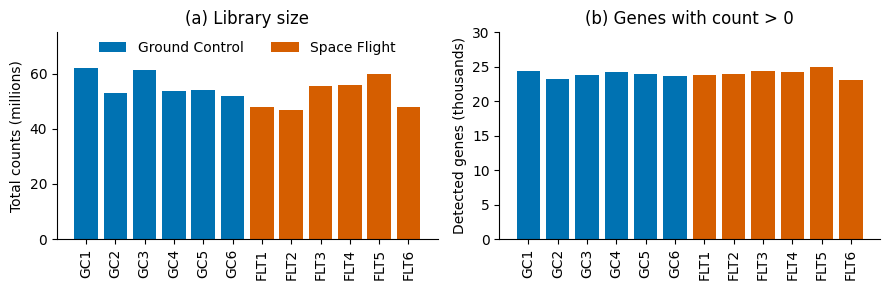

In [42]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Calculate QC metrics from the original count matrix
library_size = counts.sum(axis=0)
detected_genes = (counts > 0).sum(axis=0)

# Short sample labels to match Claude's figure
short_labels = [
    f"GC{i}" if "GC" in str(sample) else f"FLT{i}"
    for i, sample in enumerate(counts.columns, start=1)
]

# Correct labels: GC1-GC6 and FLT1-FLT6
short_labels = [
    f"GC{i}" for i in range(1, 7)
] + [
    f"FLT{i}" for i in range(1, 7)
]

# Colors
ground_color = "#0072B2"
flight_color = "#D55E00"

sample_colors = [ground_color] * 6 + [flight_color] * 6

# Create a compact figure similar to Claude's
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

# Panel (a): Library size
axes[0].bar(
    short_labels,
    library_size / 1_000_000,
    color=sample_colors,
    width=0.8
)

axes[0].set_title("(a) Library size")
axes[0].set_ylabel("Total counts (millions)")
axes[0].set_ylim(0, 75)

# Legend in the first panel only
legend_elements = [
    Patch(facecolor=ground_color, label="Ground Control"),
    Patch(facecolor=flight_color, label="Space Flight")
]

axes[0].legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

# Panel (b): Detected genes
axes[1].bar(
    short_labels,
    detected_genes / 1_000,
    color=sample_colors,
    width=0.8
)

axes[1].set_title("(b) Genes with count > 0")
axes[1].set_ylabel("Detected genes (thousands)")
axes[1].set_ylim(0, 30)

# Styling
for ax in axes:
    ax.tick_params(axis="x", rotation=90)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [43]:
print("PCA dataframe columns:")
print(pca_df.columns.tolist())
print(pca_df.head())

print("\nVolcano dataframe columns:")
print(volcano_data.columns.tolist())
print(volcano_data.head())

PCA dataframe columns:
['PC1', 'PC2', 'Condition']
                                   PC1       PC2       Condition
Mmus_C57-6J_SLS_GC_Rep1_M33 -11.481699 -0.839300  Ground.Control
Mmus_C57-6J_SLS_GC_Rep2_M34 -14.018768 -1.081059  Ground.Control
Mmus_C57-6J_SLS_GC_Rep3_M35 -11.042099 -1.565845  Ground.Control
Mmus_C57-6J_SLS_GC_Rep4_M36  -9.078677  1.183341  Ground.Control
Mmus_C57-6J_SLS_GC_Rep5_M37 -11.123937  0.451167  Ground.Control

Volcano dataframe columns:
['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj', '-log10_padj', 'Significance']
                        baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                                
ENSMUSG00000000001    926.488974       -0.054164  0.064308 -0.842256   
ENSMUSG00000000028    123.606904        0.082775  0.144909  0.571219   
ENSMUSG00000000031  80133.879533       -0.558862  0.083827 -6.666826   
ENSMUSG00000000037      8.284576       -0.246091  0.486179 -0.506174   
EN

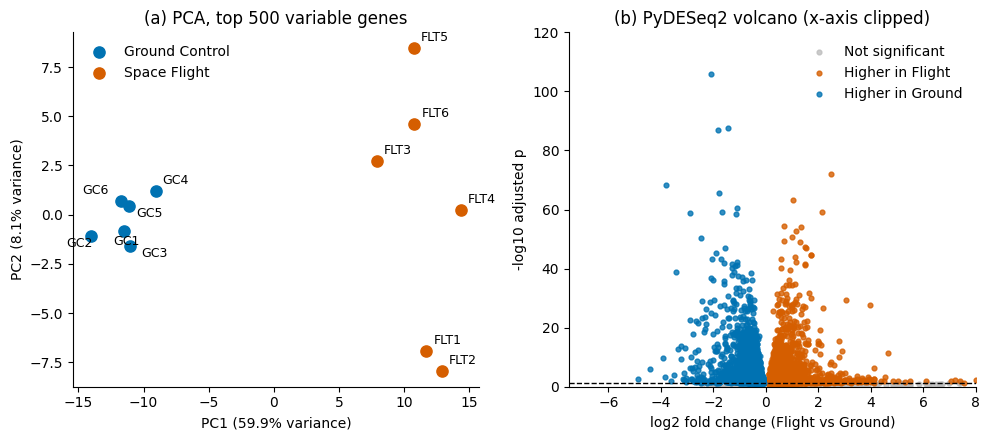

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Colors
ground_color = "#0072B2"
flight_color = "#D55E00"
gray_color = "#BDBDBD"

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# ============================================================
# (a) PCA plot
# ============================================================

ax = axes[0]

# Short sample labels
sample_labels = []

for sample in pca_df.index:
    sample = str(sample)

    if "_GC_" in sample:
        sample_number = sample.split("_GC_")[1].split("_")[0].replace("Rep", "")
        sample_labels.append(f"GC{sample_number}")

    elif "_FLT_" in sample:
        sample_number = sample.split("_FLT_")[1].split("_")[0].replace("Rep", "")
        sample_labels.append(f"FLT{sample_number}")

    else:
        sample_labels.append(sample)

# Plot each condition
for condition, color, label in [
    ("Ground.Control", ground_color, "Ground Control"),
    ("Space.Flight", flight_color, "Space Flight")
]:
    subset = pca_df[pca_df["Condition"] == condition]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        color=color,
        s=65,
        label=label,
        zorder=3
    )

# Label individual samples
for i, sample in enumerate(pca_df.index):
    x = pca_df.loc[sample, "PC1"]
    y = pca_df.loc[sample, "PC2"]
    label = sample_labels[i]

    # Slight adjustments to reduce label overlap
    if label == "GC1":
        offset = (-8, -10)
    elif label == "GC2":
        offset = (-18, -8)
    elif label == "GC3":
        offset = (8, -8)
    elif label == "GC4":
        offset = (5, 5)
    elif label == "GC5":
        offset = (5, -8)
    elif label == "GC6":
        offset = (-28, 5)
    elif label == "FLT1":
        offset = (5, 5)
    elif label == "FLT2":
        offset = (5, 5)
    elif label == "FLT3":
        offset = (5, 5)
    elif label == "FLT4":
        offset = (5, 5)
    elif label == "FLT5":
        offset = (5, 5)
    else:
        offset = (5, 5)

    ax.annotate(
        label,
        (x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("(a) PCA, top 500 variable genes")
ax.set_xlabel("PC1 (59.9% variance)")
ax.set_ylabel("PC2 (8.1% variance)")
ax.legend(loc="upper left", frameon=False)

# ============================================================
# (b) PyDESeq2 volcano plot
# ============================================================

ax = axes[1]

# Plot nonsignificant genes
nonsignificant = volcano_data[
    volcano_data["Significance"] == "Not significant"
]

ax.scatter(
    nonsignificant["log2FoldChange"],
    nonsignificant["-log10_padj"],
    color=gray_color,
    s=12,
    alpha=0.8,
    label="Not significant"
)

# Higher in Flight
higher_flight = volcano_data[
    volcano_data["Significance"] == "Higher in Flight"
]

ax.scatter(
    higher_flight["log2FoldChange"],
    higher_flight["-log10_padj"],
    color=flight_color,
    s=12,
    alpha=0.8,
    label="Higher in Flight"
)

# Higher in Ground
higher_ground = volcano_data[
    volcano_data["Significance"] == "Higher in Ground"
]

ax.scatter(
    higher_ground["log2FoldChange"],
    higher_ground["-log10_padj"],
    color=ground_color,
    s=12,
    alpha=0.8,
    label="Higher in Ground"
)

# Significance threshold
ax.axhline(
    -np.log10(0.05),
    color="black",
    linestyle="--",
    linewidth=1
)

# Match Claude's axis limits
ax.set_xlim(-7.5, 8)
ax.set_ylim(0, 120)

ax.set_title("(b) PyDESeq2 volcano (x-axis clipped)")
ax.set_xlabel("log2 fold change (Flight vs Ground)")
ax.set_ylabel("-log10 adjusted p")

ax.legend(
    loc="upper right",
    frameon=False
)

# ============================================================
# Final formatting
# ============================================================

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()